# Forelesning 9: Fartslover og koblede reaksjoner

<div class="bilde-hoyre" style="width:50%">

![fartslover](bilder/fartslover.png)

</div>

I dag bygger vi videre på Eulers metode og simulerer

- reaksjoner med flere stoffer: A + B → C
- reversible reaksjoner og dynamisk likevekt: A ⇌ B
- etterfølgende reaksjoner med et mellomprodukt: A → B → C

Til slutt ser vi på bedre metoder og ferdige løsere.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

<div class="oppgave">

**Finn feilen (repetisjon):** Programmet skal simulere en førsteordens reaksjon med $k = 0{,}10\ \mathrm{s^{-1}}$, men det inneholder **to** feil. Kjør koden, les feilmeldingen og rett feilene. Forklar for sidemannen hva hver feil gjorde.

</div>

In [ ]:
k = 0.10
A = 1.00
t = 0
dt = 0.5

times = [t]
conc = [A]

while t < 30:
    dA_dt = k * A # Feil 2: Fartsloven må ha negativt fortegn
    A = A + dA_dt * dt
    t = t + dt
    times.append(t)
conc.append(A) # Feil 1: Må rykkes inn i løkka

plt.plot(times, conc)
plt.xlabel("Time (s)")
plt.ylabel("[A] (mol/L)")
plt.show()

<div class="viktig">

Fortegnet i en fartslov forteller om stoffet **forbrukes** (negativt) eller **dannes** (positivt). Får du en konsentrasjon som vokser når den burde avta, sjekk fortegnet først.

</div>

## Del 1: A + B → C

Farten er $r = k[\mathrm{A}][\mathrm{B}]$. Støkiometrien bestemmer fortegnene:

<div class="viktig">

$$\frac{d[\mathrm{A}]}{dt} = -k[\mathrm{A}][\mathrm{B}]$$

$$\frac{d[\mathrm{B}]}{dt} = -k[\mathrm{A}][\mathrm{B}]$$

$$\frac{d[\mathrm{C}]}{dt} = k[\mathrm{A}][\mathrm{B}]$$

Likningene er **koblet**: Den samme farten avhenger av både $[\mathrm{A}]$ og $[\mathrm{B}]$, så alle konsentrasjonene må oppdateres i samme tidssteg.

</div>


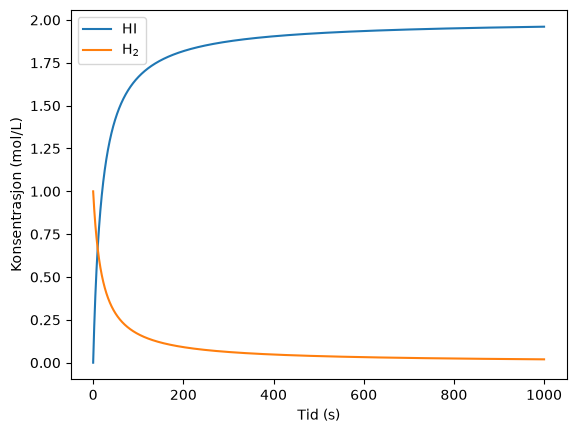

In [4]:
# Konstanter og initialbetingelser
k = 0.1
H2_0 = 1 # Startkonsentrasjon (mol/L)
I2_0 = 1 # Startkonsentrasjon (mol/L)
HI_0 = 0 # Startkonsentrasjon (mol/L)

# Tidsparametre
t0 = 0        # starttid (s)
t_slutt = 1000 # s
dt = 1E-3     # tidssteg (s)
N = int((t_slutt - t0)/dt) + 1

# Arrayer
t = np.zeros(N)
H2 = np.zeros(N)
I2 = np.zeros(N)
HI = np.zeros(N)

# Startbetingelser
t[0] = t0
H2[0] = H2_0
I2[0] = I2_0
HI[0] = HI_0

# Integrasjonsløkke
for i in range(N - 1):
    # Fartslover
    dHIdt = k*H2[i]*I2[i]
    dH2dt = -0.5*dHIdt
    dI2dt = dH2dt
    # Eulers metode
    HI[i+1] = HI[i] + dHIdt*dt # Neste verdi = forrige verdi + endringen*tidssteget
    H2[i+1] = H2[i] + dH2dt*dt
    I2[i+1] = I2[i] + dI2dt*dt
    # Oppdaterer tida
    t[i+1] = t[i] + dt

plt.plot(t, HI, label = "HI")
plt.plot(t, H2, label = "H$_2$")
plt.legend()
plt.xlabel("Tid (s)")
plt.ylabel("Konsentrasjon (mol/L)")
plt.show()

<div class="diskuter">

**Diskuter:** Hvorfor går ikke [A] mot null? Hvilken konsentrasjon nærmer [C] seg, og hvorfor?

</div>

### Kontroller kjemien: stoffbalanse
Et program er ikke riktig bare fordi programmet virker eller grafen ser pen ut. Med bare denne reaksjonen skal $[\mathrm{A}] + [\mathrm{C}] = [\mathrm{A}]_0$ og $[\mathrm{B}] + [\mathrm{C}] = [\mathrm{B}]_0$ hele tiden.

Forklar hva programmet nedenfor gjør og **fyll inn** kontrollen for B.

In [ ]:
print("Størst forskjell, A-balanse:", np.max(np.abs(H2 + HI - H2[0])))
print("Størst forskjell, B-balanse:", np.max(np.abs(I2 + HI - I2[0])

## Del 2: Reversibel reaksjon A ⇌ B

<div class="viktig">

$$\frac{d[\mathrm{A}]}{dt} = -k_f[\mathrm{A}] + k_b[\mathrm{B}] \qquad \frac{d[\mathrm{B}]}{dt} = k_f[\mathrm{A}] - k_b[\mathrm{B}]$$

Ved **dynamisk likevekt** er nettofarten null, men både framover- og bakoverreaksjonen går fortsatt.

</div>

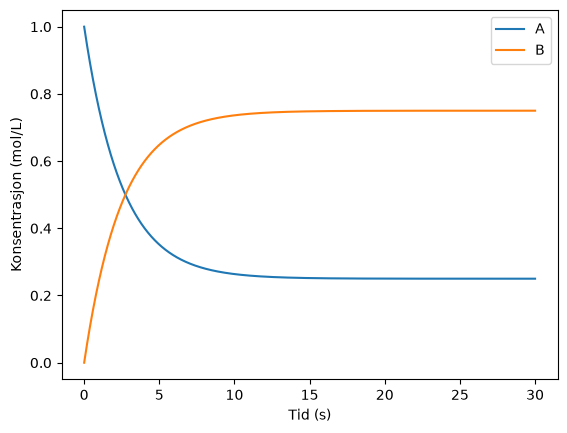

0.7499954028900022


In [7]:
# Konstanter og initialbetingelser
k_f = 0.30 # Fartskonstanten framover
k_b = 0.10 # Fartskonstanten bakover
A0 = 1.0   # mol/L
B0 = 0     # mol/L

# Tidsparametre
t0 = 0     # starttid (s)
t_slutt = 30
dt = 1E-3
N = int((t_slutt - t0)/dt) + 1

# Arrayer
t = np.zeros(N)
A = np.zeros(N)
B = np.zeros(N)
t[0] = t0
A[0] = A0
B[0] = B0

# Integrasjonsløkke
for i in range(N - 1):
    # Fartslover
    dAdt = -k_f*A[i] + k_b*B[i]
    dBdt = - dAdt
    # Eulers metode
    A[i+1] = A[i] + dAdt*dt
    B[i+1] = B[i] + dBdt*dt
    # Oppdaterer tida
    t[i+1] = t[i] + dt

# Plotting
plt.plot(t, A, label = "A")
plt.plot(t, B, label = "B")
plt.xlabel("Tid (s)")
plt.ylabel("Konsentrasjon (mol/L)")
plt.legend()
plt.show()

print(B[-1]) # Likevektskonsentrasjonen til B

<div class="oppgave">

**Prøv selv:** Lag en kode som simulerer reaksjonen.

</div>

## Del 3: Etterfølgende reaksjoner A → B → C

Mange reaksjoner går via et **mellomprodukt**. Med $k_1 = 0{,}50\ \mathrm{s^{-1}}$ og $k_2 = 0{,}10\ \mathrm{s^{-1}}$:

<div class="viktig">

$$\frac{d[\mathrm{A}]}{dt} = -k_1[\mathrm{A}] \qquad \frac{d[\mathrm{B}]}{dt} = k_1[\mathrm{A}] - k_2[\mathrm{B}] \qquad \frac{d[\mathrm{C}]}{dt} = k_2[\mathrm{B}]$$

</div>

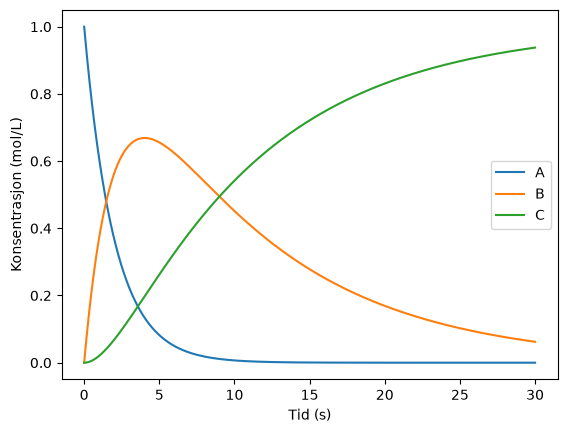

0.06222411951612197


In [10]:
# Konstanter og initialbetingelser
k1 = 0.50
k2 = 0.10
A0 = 1.0   # mol/L
B0 = 0     # mol/L
C0 = 0      # mol/L

# Tidsparametre
t0 = 0     # starttid (s)
t_slutt = 30
dt = 1E-3
N = int((t_slutt - t0)/dt) + 1

# Arrayer
t = np.zeros(N)
A = np.zeros(N)
B = np.zeros(N)
C = np.zeros(N)
t[0] = t0
A[0] = A0
B[0] = B0
C[0] = C0

# Integrasjonsløkke
for i in range(N - 1):
    # Fartslover
    dAdt = -k1*A[i]
    dBdt = k1*A[i] - k2*B[i]
    dCdt = k2*B[i]
    # Eulers metode
    A[i+1] = A[i] + dAdt*dt
    B[i+1] = B[i] + dBdt*dt
    C[i+1] = C[i] + dCdt*dt
    # Oppdaterer tida
    t[i+1] = t[i] + dt

# Plotting
plt.plot(t, A, label = "A")
plt.plot(t, B, label = "B")
plt.plot(t, C, label = "C")
plt.xlabel("Tid (s)")
plt.ylabel("Konsentrasjon (mol/L)")
plt.legend()
plt.show()

print(B[-1]) # Likevektskonsentrasjonen til B

<div class="oppgave">

**Prøv selv:** Skriv de tre Euler-stegene selv. Finn tidspunktet der [B] er størst med `np.argmax`.

</div>

In [ ]:
k1 = 0.50
k2 = 0.10
dt = 0.01
t = np.arange(0, 40 + dt, dt)

A = np.zeros(len(t))
B = np.zeros(len(t))
C = np.zeros(len(t))
A[0] = 1.0

for n in range(len(t) - 1):
    ??

plt.plot(t, A, label="[A]")
plt.plot(t, B, label="[B]")
plt.plot(t, C, label="[C]")
plt.xlabel("Time (s)")
plt.ylabel("Concentration (mol/L)")
plt.legend()
plt.show()

i_max = ??
print(f"[B] is largest at t = {t[i_max]:.2f} s")

## Del 4: Bedre metoder og ferdige løsere

<div class="bilde-hoyre" style="width:38%">

![Runge-Kutta 4 og Eulers metode](bilder/rk4_euler_meme.png)

</div>

Euler bruker bare stigningen i **starten** av hvert steg. **Runge-Kutta 4** (RK4) bruker fire stigninger i hvert steg og veier dem sammen.

<div class="viktig">

| Metode | Feilen når $\Delta t$ halveres |
|---|---|
| Euler (orden 1) | halveres |
| RK4 (orden 4) | blir 16 ganger mindre |

For $d[\mathrm{A}]/dt = -0{,}15[\mathrm{A}]$ med $\Delta t = 1$ s er feilen etter 10 s omtrent $3 \cdot 10^{-2}$ med Euler og $2 \cdot 10^{-6}$ med RK4.

</div>

### `solve_ivp`
I praksis bruker vi testede løsere. `solve_ivp` fra SciPy velger selv tidssteget. Vi skriver modellen som én funksjon som tar inn alle konsentrasjonene og returnerer alle de deriverte.

In [12]:
from scipy.integrate import solve_ivp

def fartslover(t, c): # c kan være på formen c = [A0, B0, C0]
    k1 = 0.30
    k2 = 0.10
    A, B, C = c
    dAdt = -k1*A
    dBdt = k1*A - k2*B
    dCdt = k2*B
    return [dAdt, dBdt, dCdt]
     
resultat = solve_ivp(fartslover, [0, 100], [1, 0, 0], method = "BDF")

t = resultat.t
A = resultat.y[0]
B = resultat.y[1]
C = resultat.y[2]

plt.plot(t, A)
plt.plot(t, B)
plt.plot(t, C)

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  2.403e-04 ...  9.979e+01  1.000e+02]
        y: [[ 1.000e+00  9.999e-01 ... -3.255e-10 -2.961e-10]
            [ 0.000e+00  7.208e-05 ...  6.849e-05  6.708e-05]
            [ 0.000e+00  1.462e-09 ...  9.999e-01  9.999e-01]]
      sol: None
 t_events: None
 y_events: None
     nfev: 142
     njev: 1
      nlu: 17

<div class="bilde-hoyre" style="width:42%">

![Forward Euler og Backward Euler](bilder/forward_backward_euler.png)
<p class="kreditering">Forward Euler og Backward Euler</p>

</div>

<div class="viktig">

**En god simuleringsvane**

1. Er fortegnene i fartslovene riktige ut fra støkiometrien?
2. Endrer løsningen seg hvis tidssteget reduseres?
3. Er stoffbalansen bevart?
4. Stemmer grensetilfellene med kjemisk intuisjon, for eksempel likevekt eller fullstendig omsetning?

</div>

__Oppgaver__:
1. Simuler A + B → C med $k = 0{,}05$ L/(mol·s), $[\mathrm{A}]_0 = 1{,}00$ M og $[\mathrm{B}]_0 = 0{,}60$ M. Kontroller stoffbalansen. Hva skjer når de to startkonsentrasjonene er like?
2. For A ⇌ B med $k_f = 0{,}40\ \mathrm{s^{-1}}$ og $k_b = 0{,}10\ \mathrm{s^{-1}}$: Simuler til systemet er nær likevekt. Finn omtrent når $[\mathrm{B}]$ har nådd 99 % av likevektsverdien.
3. For A → B → C: Hvordan endrer tidspunktet og høyden til maksimum for [B] seg når $k_2$ øker? Test minst fire verdier og lag et plott.
4. Løs førsteordensreaksjonen med Euler og RK4 med samme tidssteg, og sammenlikn begge med den analytiske løsningen. Hvor lite må tidssteget være for at Euler skal bli like nøyaktig som RK4 med $\Delta t = 1$ s?
5. Løs A + B → C med `solve_ivp`. Undersøk feltene `success`, `message` og `nfev` i resultatet. Hva forteller de?